# 1 · See: what the Play Store data really contains

**Syllabus:** Module 1 (properties of data, repositories), Module 2 (import, select,
filter, missing values).

Two sources:

* **2018 snapshot** (Kaggle, Lavanya Gupta, CC BY 3.0): 10,841 app listings and
  64,295 user reviews, scraped from the Google Play Store in August 2018.
* **2026 scrape** (this project, `export/scrape_2026.py`): the same store today, 66
  search phrases across all 33 categories, every hit looked up for full details.

Before anything is modelled, every problem in the data is found and fixed, and every
fix is counted.

In [1]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import common as C

C.style()
raw = C.load_raw()
print(raw.shape)
raw.head()

(10841, 13)


,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver
0,Photo Editor & Candy Camera & Grid & ScrapBook,ART_AND_DESIGN,4.1,159,19M,"10,000+",Free,0,Everyone,Art & Design,"January 7, 2018",1.0.0,4.0.3 and up
1,Coloring book moana,ART_AND_DESIGN,3.9,967,14M,"500,000+",Free,0,Everyone,Art & Design;Pretend Play,"January 15, 2018",2.0.0,4.0.3 and up
2,"U Launcher Lite – FREE Live Cool Themes, Hide ...",ART_AND_DESIGN,4.7,87510,8.7M,"5,000,000+",Free,0,Everyone,Art & Design,"August 1, 2018",1.2.4,4.0.3 and up
3,Sketch - Draw & Paint,ART_AND_DESIGN,4.5,215644,25M,"50,000,000+",Free,0,Teen,Art & Design,"June 8, 2018",Varies with device,4.2 and up
4,Pixel Draw - Number Art Coloring Book,ART_AND_DESIGN,4.3,967,2.8M,"100,000+",Free,0,Everyone,Art & Design;Creativity,"June 20, 2018",1.1,4.4 and up


## 1.1 Problems found in the raw table

* One row has every value shifted one column to the left (its Category reads `1.9`,
  its Installs reads `Free`). It cannot be repaired with confidence, so it is dropped.
* Numbers stored as text: Installs (`10,000+`), Price (`$4.99`), Size (`19M`, `201k`,
  `Varies with device`), Android version (`4.0.3 and up`).
* The same app appears more than once: the store was scraped more than once (the copies
  differ only in review count), and some apps are listed under two categories.

In [2]:
apps, log = C.clean(raw)
print(json.dumps(log, indent=1))
C.record("data.kaggle", log)
C.record("data.kaggle.columns", list(raw.columns))
print(raw["Installs"].value_counts().head(8))

{
 "raw_rows": 10841,
 "shifted_rows_dropped": 1,
 "duplicate_rows": 1181,
 "apps_in_two_categories": 85,
 "apps": 9659,
 "missing_rating": 1463,
 "size_varies": 1228
}
Installs
1,000,000+     1579
10,000,000+    1252
100,000+       1169
10,000+        1054
1,000+          907
5,000,000+      752
100+            719
500,000+        539
Name: count, dtype: int64


**Installs is a bucket, not a count.** `1,000,000+` means "at least a million". The
lower bound is kept, and every model uses its base-10 logarithm, so one step means ten
times more installs.

## 1.2 Missing values

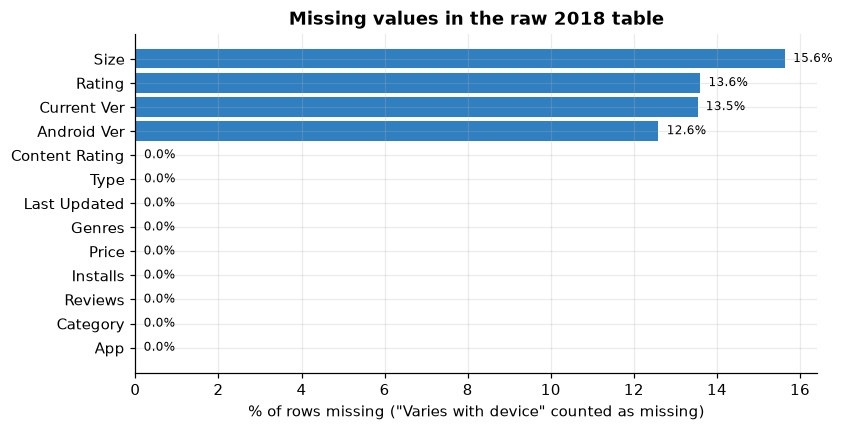

In [3]:
miss = raw.replace("Varies with device", np.nan).isna().mean().sort_values() * 100
fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(miss.index, miss.values, color=C.PALETTE["main"])
for i, v in enumerate(miss.values):
    ax.text(v + 0.2, i, f"{v:.1f}%", va="center", fontsize=8)
ax.set_xlabel("% of rows missing (\"Varies with device\" counted as missing)")
ax.set_title("Missing values in the raw 2018 table")
C.save(fig, "see_missing")
C.record("data.missing_pct", miss.round(2).to_dict())

**Rating** is missing for about one app in seven. The cell below shows these are apps
with very few installs, consistent with the store showing no rating until enough
people have rated. So rating is
*missing not at random*, and filling it with the mean would invent ratings for exactly
the apps that have none. Rating is left missing, and every model that needs it says so.

In [4]:
has = apps["rating"].notna()
by = apps.groupby(has)["installs"].median()
print("median installs, rated vs unrated:", by.to_dict())
C.record("data.median_installs_rated", int(by[True])); C.record("data.median_installs_unrated", int(by[False]))

median installs, rated vs unrated: {False: 100.0, True: 100000.0}


## 1.3 Outliers

Two columns have extreme values. Reviews spans eight orders of magnitude (heavy tail,
real). Price has a cluster of apps near $400: the "I am rich" apps, which do nothing
and exist only to be expensive. They are real listings, so they stay, but every model
uses log(1 + price) so they cannot dominate.

C:\Users\Cleo\AppData\Local\Temp\ipykernel_57336\1382418787.py:2: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  axes[0].boxplot(np.log10(apps["reviews"] + 1), vert=False, widths=0.6)
C:\Users\Cleo\AppData\Local\Temp\ipykernel_57336\1382418787.py:5: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  axes[1].boxplot(paid["price"], vert=False, widths=0.6)


18 apps cost $200 or more, e.g. ['most expensive app (H)', "💎 I'm rich", "I'm Rich - Trump Edition", 'I am rich', 'I am Rich Plus']


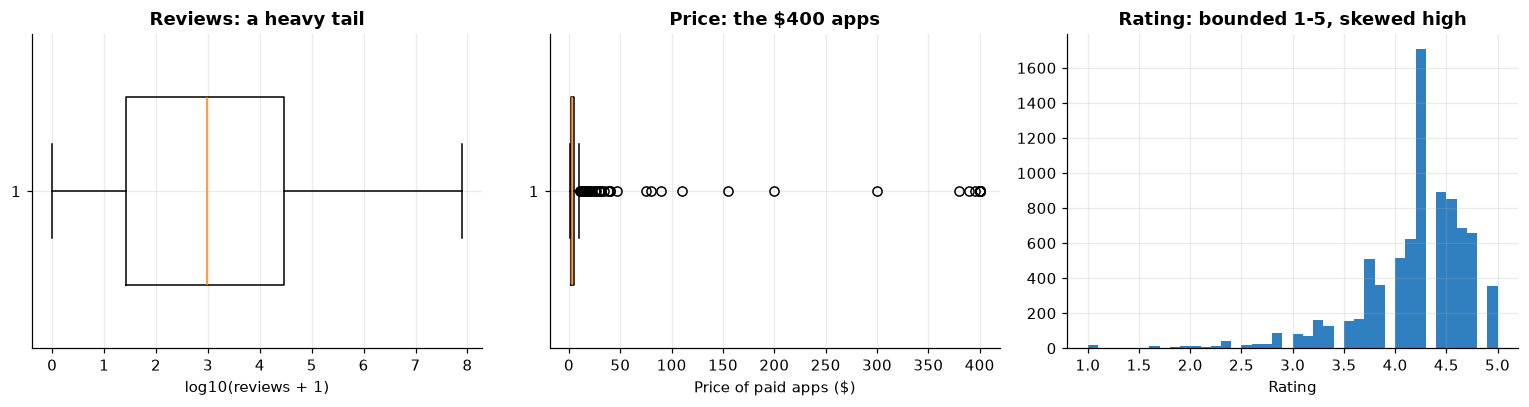

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
axes[0].boxplot(np.log10(apps["reviews"] + 1), vert=False, widths=0.6)
axes[0].set_xlabel("log10(reviews + 1)"); axes[0].set_title("Reviews: a heavy tail")
paid = apps[apps["paid"] == 1]
axes[1].boxplot(paid["price"], vert=False, widths=0.6)
axes[1].set_xlabel("Price of paid apps ($)"); axes[1].set_title("Price: the $400 apps")
axes[2].hist(apps["rating"].dropna(), bins=40, color=C.PALETTE["main"])
axes[2].set_xlabel("Rating"); axes[2].set_title("Rating: bounded 1-5, skewed high")
fig.tight_layout(); C.save(fig, "see_outliers")
rich = paid[paid["price"] >= 200]
print(len(rich), "apps cost $200 or more, e.g.", rich["app"].head(5).tolist())
q1, q3 = np.percentile(np.log10(apps["reviews"] + 1), [25, 75])
iqr_out = int((np.log10(apps["reviews"] + 1) > q3 + 1.5 * (q3 - q1)).sum())
C.record("data.price_200_plus", len(rich)); C.record("data.max_price", float(apps["price"].max()))
C.record("data.reviews_iqr_outliers_log", iqr_out)

## 1.4 The reviews table

64,295 rows, but a review text exists for only some of them, and only 1,074 apps
appear at all. The figure below shows they lean heavily towards popular apps. That
matters for anything learned from reviews: it describes what users say about
established apps, not about apps that never took off.

{
 "rows": 64295,
 "rows_with_text": 37427,
 "apps": 1074,
 "apps_with_text": 865,
 "apps_matched": 816,
 "sentiment_share": {
  "Positive": 0.641,
  "Negative": 0.221,
  "Neutral": 0.138
 }
}


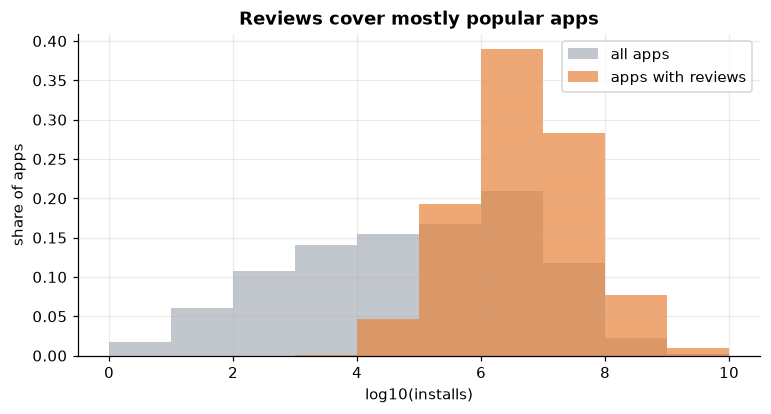

In [6]:
rv_raw = pd.read_csv(C.DATA / "googleplaystore_user_reviews.csv")
rv = C.load_reviews()
cover = apps["app"].isin(rv["app"])
info = {"rows": len(rv_raw), "rows_with_text": len(rv), "apps": int(rv_raw["App"].nunique()),
        "apps_with_text": int(rv["app"].nunique()), "apps_matched": int(cover.sum()),
        "sentiment_share": rv["sentiment"].value_counts(normalize=True).round(3).to_dict()}
print(json.dumps(info, indent=1)); C.record("data.reviews", info)

fig, ax = plt.subplots(figsize=(8, 3.8))
bins = np.arange(0, 10.5, 1)
ax.hist(apps["log_installs"], bins=bins, density=True, alpha=0.6, label="all apps", color=C.PALETTE["muted"])
ax.hist(apps.loc[cover, "log_installs"], bins=bins, density=True, alpha=0.7, label="apps with reviews", color=C.PALETTE["accent"])
ax.set_xlabel("log10(installs)"); ax.set_ylabel("share of apps"); ax.legend()
ax.set_title("Reviews cover mostly popular apps")
C.save(fig, "see_reviews_coverage")
C.record("data.reviews.median_log_installs_covered", float(apps.loc[cover, "log_installs"].median()))
C.record("data.reviews.median_log_installs_all", float(apps["log_installs"].median()))

## 1.5 The 2026 scrape

Search results are ranked by Google, so the scrape is a sample of the apps users find
first, not of the whole store. It is used to compare markets (chapter 2) and to test
whether models built on 2018 still hold eight years later (chapter 6), never to
estimate store-wide totals.

In [7]:
now = C.load_2026()
slog = json.loads((C.DATA / "scrape_log.json").read_text())
info = {**slog, "categories": int(now["category"].nunique()), "success_share": round(float(now["success"].mean()), 3),
        "missing_rating": int(now["rating"].isna().sum()), "paid_share": round(float(now["paid"].mean()), 3)}
print(json.dumps(info, indent=1)); C.record("data.scrape", info)
C.record("data.kaggle.success_share", round(float(apps["success"].mean()), 3))
C.record("data.kaggle.paid_share", round(float(apps["paid"].mean()), 3))
C.record("data.kaggle.categories", int(apps["category"].nunique()))
C.record("data.kaggle.genres", int(apps["genre"].nunique()))
now[["app", "category", "installs", "rating", "n_ratings", "released"]].head()

{
 "scraped_at": "2026-10-26T17:43:57+00:00",
 "store": "US, English",
 "queries": 66,
 "search_hits": 1669,
 "apps_with_details": 1668,
 "failed_lookups": 1,
 "package": "google-play-scraper",
 "categories": 33,
 "success_share": 0.689,
 "missing_rating": 128,
 "paid_share": 0.022
}


,app,category,installs,rating,n_ratings,released
0,Sketchbook,ART_AND_DESIGN,100000000,4.070069,706904.0,"Oct 8, 2014"
1,ibis Paint X,ART_AND_DESIGN,100000000,4.474859,3017683.0,"Feb 27, 2014"
2,AR Drawing: Sketch & Paint,ART_AND_DESIGN,10000000,4.099335,848540.0,"Jun 2, 2023"
3,Sketch Pro: Draw & Create Art,ART_AND_DESIGN,1000000,4.594771,33875.0,"Dec 7, 2023"
4,Infinite Painter,ART_AND_DESIGN,10000000,4.489973,247038.0,"Apr 2, 2012"
